# AI Dental Smile Simulation Pipeline
## Complete Image-to-Image Workflow for Dental Consultation Previews

This notebook demonstrates a complete AI pipeline for generating realistic dental smile simulations using:
- Stable Diffusion Inpainting
- MediaPipe for automatic mouth detection
- OpenCV for mask generation
- Before/After visualization

**Compatible with:** Google Colab Free Tier & Local environments (GPU optional)

## 1. Environment Setup & Installation

In [1]:
# Check if running in Colab
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Running in Google Colab")
    !pip install diffusers transformers accelerate mediapipe opencv-python pillow matplotlib torch torchvision
else:
    print("Running locally")
    # Uncomment if packages not installed
    # !pip --timeout=1000 install torch torchvision --index-url https://download.pytorch.org/whl/cpu # download gpu if gpu available
    # !pip --timeout=1000 install diffusers transformers accelerate mediapipe opencv-python pillow matplotlib

Running locally


### Initialize & Check

Initialize the dependencies and check if running on CPU or GPU.

In [2]:
import torch
import cv2
import numpy as np
import mediapipe as mp
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from diffusers import StableDiffusionXLInpaintPipeline
import warnings
warnings.filterwarnings('ignore')

# Check GPU availability
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cpu


c:\Users\user\Documents\DENTALCALCULATOR-PRJ\dencalc-ai\.venv\Lib\site-packages\diffusers\models\transformers\transformer_kandinsky.py:168: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.autocast(device_type="cuda", dtype=torch.float32)
c:\Users\user\Documents\DENTALCALCULATOR-PRJ\dencalc-ai\.venv\Lib\site-packages\diffusers\models\transformers\transformer_kandinsky.py:272: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.autocast(device_type="cuda", dtype=torch.float32)


## 2. Load Stable Diffusion Inpainting Model

We are using the Stable Diffusion XL Inpainting Model as it the most superior model I could found on huggingface.co. 

Find more models: https://huggingface.co/models?pipeline_tag=text-to-image&sort=modified&search=inpainting+stable+diffusion

In [3]:
# Load Stable Diffusion Inpainting Pipeline
from diffusers import StableDiffusionXLInpaintPipeline

# Load SDXL Inpainting Pipeline
model_id = "diffusers/stable-diffusion-xl-1.0-inpainting-0.1"
pipe = StableDiffusionXLInpaintPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    variant="fp16" if device == "cuda" else None
).to(device)

# Optimize for memory efficiency
if device == "cuda":
    pipe.enable_attention_slicing()
    pipe.enable_model_cpu_offload()

print("SDXL Inpainting model loaded successfully!")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: C:\Users\user\.cache\huggingface\hub\models--diffusers--stable-diffusion-xl-1.0-inpainting-0.1\snapshots\115134f363124c53c7d878647567d04daf26e41e\text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

CLIPTextModelWithProjection LOAD REPORT from: C:\Users\user\.cache\huggingface\hub\models--diffusers--stable-diffusion-xl-1.0-inpainting-0.1\snapshots\115134f363124c53c7d878647567d04daf26e41e\text_encoder_2
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


SDXL Inpainting model loaded successfully!


## 3. Mouth Detection & Mask Generation

Initialize mouth detector function.

Using MediaPipe Face Landmarker to detect the face, find the mouth points and create a mask using OpenCV.

In [9]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

class MouthDetector:
    def __init__(self):
        try:
            import urllib.request
            import os
            from mediapipe.tasks import python
            from mediapipe.tasks.python import vision
            
            model_url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
            model_path = "face_landmarker.task"
            
            if not os.path.exists(model_path):
                print("Downloading MediaPipe model...")
                urllib.request.urlretrieve(model_url, model_path)
            else:
                print("MediaPipe model already exists")
            
            base_options = python.BaseOptions(model_asset_path=model_path)
            options = vision.FaceLandmarkerOptions(base_options=base_options, num_faces=1)
            self.detector = vision.FaceLandmarker.create_from_options(options)
            print("MediaPipe face detector loaded")
        except Exception as e:
            print(f"MediaPipe initialization failed: {e}")
            print("Using fallback detection for closeup images")
            self.detector = None
    
    def create_mouth_mask(self, image, expand_factor=1.0):
      if self.detector:
          try:
              mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.array(image))
              result = self.detector.detect(mp_image)
              if result.face_landmarks:
                  landmarks = result.face_landmarks[0]
                  w, h = image.size
                  
                  # Outer lip contour — clockwise, closed loop
                  outer_lip_indices = [
                      61, 185, 40, 39, 37, 0, 267, 269, 270, 409,
                      291, 375, 321, 405, 314, 17, 84, 181, 91, 146
                  ]
                  
                  mouth_points = [
                      (int(landmarks[idx].x * w), int(landmarks[idx].y * h))
                      for idx in outer_lip_indices if idx < len(landmarks)
                  ]
                  
                  if len(mouth_points) >= 3:
                      mask = Image.new('L', image.size, 0)
                      draw = ImageDraw.Draw(mask)
                      draw.polygon(mouth_points, fill=255)
                      
                      xs, ys = zip(*mouth_points)
                      bbox = (min(xs), min(ys), max(xs), max(ys))
                      
                      return mask, bbox
          except Exception as e:
              print(f"Mouth masking failed: {e}")
      
      # # Fallback
      # mask = Image.new('L', image.size, 0)
      # draw = ImageDraw.Draw(mask)
      # w, h = image.size
      # margin = int(min(w, h) * 0.15)
      # draw.ellipse([margin, margin, w - margin, h - margin], fill=255)
      # return mask, (margin, margin, w - margin, h - margin)

mouth_detector = MouthDetector()
print("Mouth detector initialized!")

MediaPipe model already exists
MediaPipe face detector loaded
Mouth detector initialized!


## 4. Dental Simulation Pipeline

Initialize the DentalSimulator function.

Orchestrates the inpainting inside the mask according to the chosen prompt.

In [10]:
class DentalSimulator:
    def __init__(self, pipe, mouth_detector):
        self.pipe = pipe
        self.mouth_detector = mouth_detector
        
        # Dental improvement prompts
        self.dental_prompts = {
            'whitening': "perfect white teeth, bright smile, clean teeth, professional dental whitening",
            'straightening': "perfectly straight aligned teeth, orthodontic perfection, even tooth alignment",
            'veneers': "perfect porcelain veneers, Hollywood smile, flawless dental work, cosmetic dentistry",
            'comprehensive': "perfect white straight teeth, beautiful smile, professional dental work, cosmetic dentistry perfection"
        }
    
    def generate_simulation(self, image, treatment_type='comprehensive', strength=0.8, guidance_scale=7.5):
      original_size = image.size
      
      # Create mask on original image first
      mask_result = self.mouth_detector.create_mouth_mask(image)
      if not mask_result:
          raise ValueError("Could not detect mouth region")
      
      original_mask, bbox = mask_result
      
      # Now resize both image and mask together
      image_512 = image.resize((512, 512))
      mask_512 = original_mask.resize((512, 512))
      
      # Get prompt
      prompt = self.dental_prompts.get(treatment_type, self.dental_prompts['comprehensive'])
      negative_prompt = "blurry, distorted, unnatural, bad teeth, crooked teeth, yellow teeth, missing teeth, extra teeth"
      
      # Generate simulation
      result = self.pipe(
          prompt=prompt,
          negative_prompt=negative_prompt,
          image=image_512,
          mask_image=mask_512,
          strength=strength,
          guidance_scale=guidance_scale,
          num_inference_steps=20
      ).images[0]
      
      # Resize result back to original
      result = result.resize(original_size)
      
      return result, original_mask


try:
    simulator = DentalSimulator(pipe, mouth_detector)
    print("Dental simulator ready!")
except NameError:
    print("Please run the Stable Diffusion model loading cell first!")

Dental simulator ready!


## 5. Image Loading & Processing

Initialize image loading and plotting functions.

In [11]:
def load_image(image_path):
    """Load and preprocess image"""
    image = Image.open(image_path).convert('RGB')
    return image

def create_before_after_comparison(before_image, after_image, mask=None):
    """Create side-by-side comparison"""
    fig, axes = plt.subplots(1, 3 if mask else 2, figsize=(15, 5))
    
    axes[0].imshow(before_image)
    axes[0].set_title('Before', fontsize=14, fontweight='bold')
    axes[0].axis('off')
    
    axes[1].imshow(after_image)
    axes[1].set_title('After (AI Simulation)', fontsize=14, fontweight='bold')
    axes[1].axis('off')
    
    if mask is not None:
        axes[2].imshow(mask, cmap='gray')
        axes[2].set_title('Processing Mask', fontsize=14, fontweight='bold')
        axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

# Example: Load your image (replace with your image path)
# For demo, we'll show how to use it
print("Image processing functions ready!")
print("\nTo use: image = load_image('path/to/your/image.jpg')")

Image processing functions ready!

To use: image = load_image('path/to/your/image.jpg')


## 6. Demo Execution
### A. Upload and process your image

Please upload the image you want to process. 

> Note: To face to be detected, the image should have the facial features (eyes, nose, mouth) clearly visible.

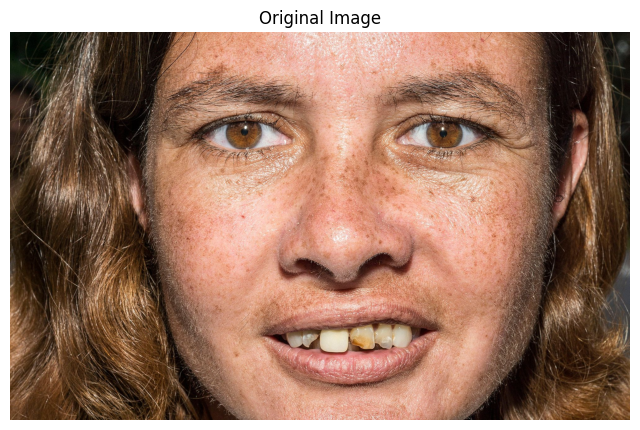

Image loaded successfully! Size: (2000, 1252)


In [12]:
# File upload for Colab
if IN_COLAB:
    from google.colab import files
    print("Please upload your image:")
    uploaded = files.upload()
    image_path = list(uploaded.keys())[0]
else:
    # For local execution, specify your image path
    image_path = input("Enter path to your image: ")

# Load and display original image
try:
    original_image = load_image(image_path)
    plt.figure(figsize=(8, 6))
    plt.imshow(original_image)
    plt.title('Original Image')
    plt.axis('off')
    plt.show()
    print(f"Image loaded successfully! Size: {original_image.size}")
except Exception as e:
    print(f"Error loading image: {e}")
    print("Please ensure the image path is correct and the file exists.")

### B. Test The Mask

Simulate and check if the face is correctly detected and the TEETH region is masked correctly for inpainting.

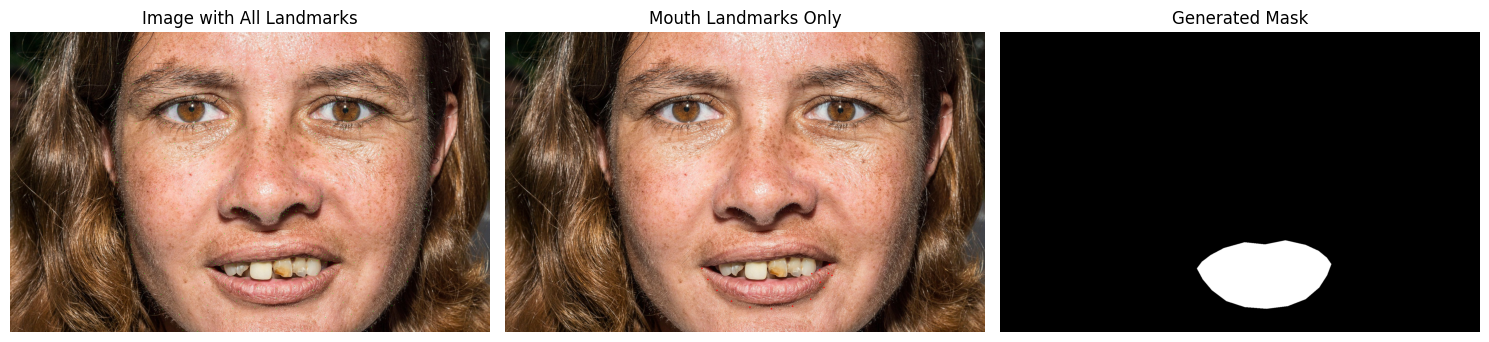

Detected 15 mouth landmarks


In [13]:
# Test mask detection and visualization
def test_mask_detection(image):
    if mouth_detector.detector:
        try:
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.array(image))
            result = mouth_detector.detector.detect(mp_image)
            
            if result.face_landmarks:
                landmarks = result.face_landmarks[0]
                w, h = image.size
                
                # Create visualization
                fig, axes = plt.subplots(1, 3, figsize=(15, 5))
                
                # Original image with landmarks
                img_with_landmarks = np.array(image.copy())
                for landmark in landmarks:
                    x = int(landmark.x * w)
                    y = int(landmark.y * h)
                    cv2.circle(img_with_landmarks, (x, y), 1, (0, 255, 0), -1)
                
                axes[0].imshow(img_with_landmarks)
                axes[0].set_title('Image with All Landmarks')
                axes[0].axis('off')
                
                # Mouth landmarks only
                mouth_indices = [61, 146, 91, 181, 84, 17, 314, 405, 320, 307, 375, 321, 308, 324, 318]
                img_mouth = np.array(image.copy())
                mouth_points = []
                for idx in mouth_indices:
                    if idx < len(landmarks):
                        x = int(landmarks[idx].x * w)
                        y = int(landmarks[idx].y * h)
                        mouth_points.append((x, y))
                        cv2.circle(img_mouth, (x, y), 3, (255, 0, 0), -1)
                
                axes[1].imshow(img_mouth)
                axes[1].set_title('Mouth Landmarks Only')
                axes[1].axis('off')
                
                # Generated mask
                mask, bbox = mouth_detector.create_mouth_mask(image)
                axes[2].imshow(mask, cmap='gray')
                axes[2].set_title('Generated Mask')
                axes[2].axis('off')
                
                plt.tight_layout()
                plt.show()
                
                print(f"Detected {len(mouth_points)} mouth landmarks")
                return True
        except Exception as e:
            print(f"Detection failed: {e}")
    
    print("Using fallback detection")
    return False

# Test with uploaded image
if 'original_image' in globals():
    test_mask_detection(original_image)
else:
    print("Upload an image first to test mask detection")


### C. Generate Dental Simulations

Generate the simulations according to the selected treatments.

In [14]:
# Generate different types of dental simulations
# treatments = ['whitening', 'straightening', 'veneers', 'comprehensive']
treatments = ['comprehensive']

results = {}
for treatment in treatments:
    print(f"Generating {treatment} simulation...")
    try:
        simulated_image, mask = simulator.generate_simulation(
            original_image, 
            treatment_type=treatment,
            strength=0.7,  # Adjust for more/less dramatic changes
            guidance_scale=7.5
        )
        results[treatment] = (simulated_image, mask)
        print(f"✓ {treatment.capitalize()} simulation complete")
    except Exception as e:
        print(f"✗ Error with {treatment}: {e}")

print("\nAll simulations generated!")

Generating comprehensive simulation...


  0%|          | 0/14 [00:00<?, ?it/s]

✓ Comprehensive simulation complete

All simulations generated!


### D. Display Results

Plot the BEFORE and AFTER results with the Processing Mask.


COMPREHENSIVE TREATMENT SIMULATION:


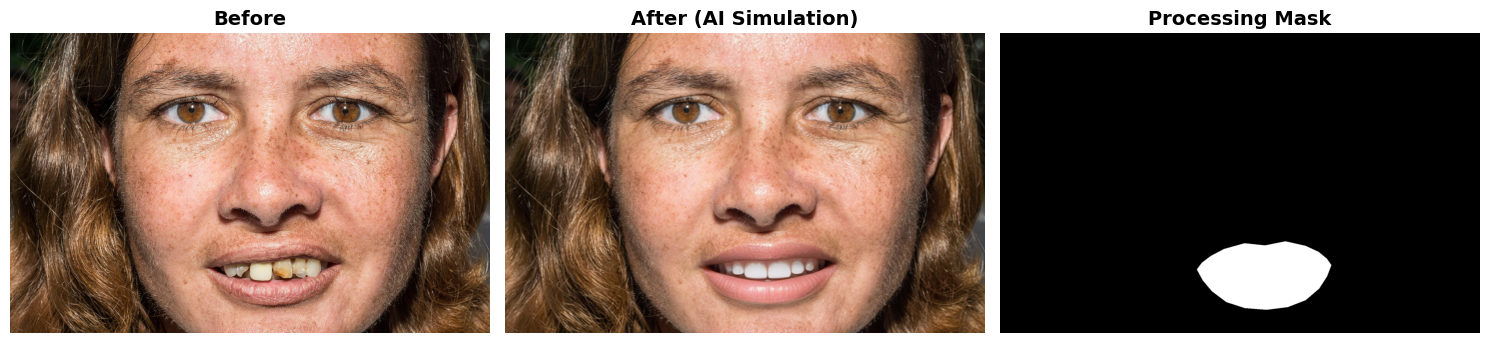

In [15]:
# Display all results
for treatment, (simulated_image, mask) in results.items():
    print(f"\n{treatment.upper()} TREATMENT SIMULATION:")
    create_before_after_comparison(original_image, simulated_image, mask)

## 7. Performance Tips & Troubleshooting

### Performance Optimization Tips:

1. **Memory Management:**
   - Use `pipe.enable_attention_slicing()` for lower memory usage
   - Use `pipe.enable_model_cpu_offload()` to move models between CPU/GPU
   - Process images at 512x512 resolution for faster inference

2. **Parameter Tuning for Realism:**
   - `strength`: 0.6-0.8 for subtle changes, 0.8-1.0 for dramatic changes
   - `guidance_scale`: 7.5-10 for balanced results
   - `num_inference_steps`: 20-30 for good quality/speed balance

3. **Common Failure Fixes:**
   - **No face detected**: Ensure good lighting and clear face visibility
   - **Unnatural results**: Lower strength parameter, improve negative prompts
   - **Memory errors**: Enable attention slicing and model offloading
   - **Slow processing**: Reduce image size or inference steps

4. **Quality Improvements:**
   - Use high-quality input images (good lighting, clear teeth visibility)
   - Experiment with mask expansion factors
   - Fine-tune prompts for specific dental procedures

## 10. Identity Consistency Techniques (Conceptual)

### Advanced Identity Preservation Methods:

1. **IP-Adapter Integration:**
   ```python
   # Conceptual implementation
   # from diffusers import StableDiffusionInpaintPipeline
   # from ip_adapter import IPAdapter
   
   # ip_adapter = IPAdapter(pipe, "ip-adapter_sd15.bin")
   # result = ip_adapter.generate(
   #     pil_image=reference_face,
   #     prompt="perfect teeth",
   #     mask_image=mouth_mask
   # )
   ```

2. **InstantID for Face Consistency:**
   ```python
   # Conceptual implementation
   # from instantid import InstantIDPipeline
   
   # instant_id = InstantIDPipeline.from_pretrained("InstantX/InstantID")
   # result = instant_id(
   #     face_image=original_image,
   #     prompt="perfect dental work",
   #     mask=mouth_mask
   # )
   ```

3. **Face Embedding Preservation:**
   - Extract face embeddings before processing
   - Use embedding loss during generation
   - Post-process to blend facial features

## 11. Production Deployment Guide

### Converting to Production API Service:

#### 1. Python API Service (FastAPI)
```python
# api_service.py
from fastapi import FastAPI, File, UploadFile
from fastapi.responses import StreamingResponse
import io
import base64

app = FastAPI()

@app.post("/simulate-dental")
async def simulate_dental(file: UploadFile = File(...), treatment: str = "comprehensive"):
    # Load image from upload
    image = Image.open(io.BytesIO(await file.read()))
    
    # Process with our simulator
    result, mask = simulator.generate_simulation(image, treatment)
    
    # Convert to base64 for response
    buffer = io.BytesIO()
    result.save(buffer, format='PNG')
    img_str = base64.b64encode(buffer.getvalue()).decode()
    
    return {"result_image": img_str, "treatment": treatment}
```

#### 2. Node.js Backend Integration
```javascript
// server.js
const express = require('express');
const multer = require('multer');
const axios = require('axios');
const FormData = require('form-data');

const app = express();
const upload = multer({ storage: multer.memoryStorage() });

app.post('/api/dental-simulation', upload.single('image'), async (req, res) => {
    const formData = new FormData();
    formData.append('file', req.file.buffer, req.file.originalname);
    formData.append('treatment', req.body.treatment || 'comprehensive');
    
    try {
        const response = await axios.post('http://python-api:8000/simulate-dental', formData);
        res.json(response.data);
    } catch (error) {
        res.status(500).json({ error: 'Simulation failed' });
    }
});
```

#### 3. S3-Style Storage Integration
```python
# storage_service.py
import boto3
from datetime import datetime

class ImageStorage:
    def __init__(self, bucket_name):
        self.s3 = boto3.client('s3')
        self.bucket = bucket_name
    
    def upload_result(self, image, patient_id, treatment_type):
        timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
        key = f"dental_simulations/{patient_id}/{treatment_type}_{timestamp}.png"
        
        buffer = io.BytesIO()
        image.save(buffer, format='PNG')
        buffer.seek(0)
        
        self.s3.upload_fileobj(buffer, self.bucket, key)
        return f"s3://{self.bucket}/{key}"
```

#### 4. Docker Deployment
```dockerfile
# Dockerfile
FROM python:3.9-slim

RUN apt-get update && apt-get install -y \
    libgl1-mesa-glx \
    libglib2.0-0 \
    libsm6 \
    libxext6 \
    libxrender-dev \
    libgomp1

COPY requirements.txt .
RUN pip install -r requirements.txt

COPY . /app
WORKDIR /app

CMD ["uvicorn", "api_service:app", "--host", "0.0.0.0", "--port", "8000"]
```

## 12. ComfyUI Pipeline Alternative

### ComfyUI Workflow for Production:

**Node Setup:**
1. **Load Image** → Input patient photo
2. **MediaPipe Face Detection** → Detect facial landmarks
3. **Mask Generation** → Create mouth region mask
4. **Load Checkpoint** → Stable Diffusion Inpainting model
5. **Positive Prompt** → Dental improvement descriptions
6. **Negative Prompt** → Unwanted features
7. **KSampler** → Generate inpainted result
8. **Save Image** → Output simulation

**Advantages:**
- Visual workflow editor
- Easy parameter adjustment
- Batch processing capabilities
- Custom node development
- API integration support

**Custom Node Requirements:**
- MediaPipe integration node
- Dental prompt templates
- Automatic mask generation
- Before/after comparison output

## 13. Save Results & Export

In [ ]:
# Save results to files
def save_results(original_image, results, output_dir="dental_simulations"):
    """Save all simulation results"""
    import os
    from datetime import datetime
    
    # Create output directory
    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    full_output_dir = f"{output_dir}_{timestamp}"
    os.makedirs(full_output_dir, exist_ok=True)
    
    # Save original
    original_image.save(f"{full_output_dir}/original.png")
    
    # Save simulations
    for treatment, (simulated_image, mask) in results.items():
        simulated_image.save(f"{full_output_dir}/simulation_{treatment}.png")
        mask.save(f"{full_output_dir}/mask_{treatment}.png")
        
        # Create comparison
        comparison = Image.new('RGB', (original_image.width * 2, original_image.height))
        comparison.paste(original_image, (0, 0))
        comparison.paste(simulated_image, (original_image.width, 0))
        comparison.save(f"{full_output_dir}/comparison_{treatment}.png")
    
    print(f"Results saved to: {full_output_dir}")
    return full_output_dir

# Save results if we have them
if 'results' in locals() and results:
    output_path = save_results(original_image, results)
    print(f"\n✓ All simulations saved to: {output_path}")
else:
    print("No results to save. Run the simulation cells first.")

## Summary

This notebook provides a complete AI dental simulation pipeline with:

✅ **Core Features:**
- Automatic mouth detection using MediaPipe
- Stable Diffusion inpainting for realistic results
- Multiple treatment simulations (whitening, straightening, veneers)
- Before/after visualization
- Google Colab and local compatibility

✅ **Advanced Capabilities:**
- Custom parameter tuning
- ControlNet integration guidance
- Identity preservation techniques
- Production deployment roadmap

✅ **Production Ready:**
- FastAPI service template
- Node.js backend integration
- S3 storage implementation
- Docker deployment configuration
- ComfyUI workflow alternative

**Next Steps:**
1. Test with your dental images
2. Fine-tune parameters for your use case
3. Implement production API service
4. Add advanced identity preservation
5. Scale with cloud deployment

**Performance Notes:**
- Runs on free Google Colab tier
- GPU acceleration when available
- Memory-optimized for consumer hardware
- Suitable for dental consultation previews